# Computer Vision 2026-2027 - NOVA FCT

## Project Stage 1 - Shot boundary detection and recurring scenes

**Authors**:
- 73213, Tomás Alexandre, tf.alexandre@campus.fct.unl.pt
- 77580, Ana Francisco, am.francisco@campus.fct.unl.pt

## 1. Introduction

Um vídeo editado é uma sequência de *shots* (tomadas contínuas de uma câmara) separados por transições; neste projeto todas as transições são cortes secos. O trabalho tem três partes: (1) detetar os cortes medindo a diferença entre frames consecutivas com três sinais (diferença de píxeis, histogramas de cor e *Edge Change Ratio*); (2) eliminar falsos alarmes, como *flashes* e movimento de câmara, verificando cada candidato com *features* locais (SIFT); e (3) agrupar os *shots* que mostram a mesma cena.

Todos os parâmetros foram escolhidos nos vídeos de desenvolvimento (`dev_01`, `dev_02`); os vídeos de teste só são usados para os resultados finais (secção 5). O código está em `tp1.py` e este notebook importa-o.

## 2. Part 1 - Frame dissimilarity and hard cuts

In [21]:
%load_ext autoreload
%autoreload 2

import os
import json
import glob
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt

from tp1 import (
    read_frames,
    compute_pixel_diff_signal,
    compute_histogram_signal,
    compute_ecr_signal,
    detect_cuts,
    detect_cuts_combined,
    compute_edges
)
import plotting
import metrics

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Task 1 - Leitura e redução das frames

Os vídeos têm 640×360 a 25 fps. Lemos todas as frames com `read_frames`, que as reduz para **320×180** (metade em cada dimensão, mantendo a proporção 16:9) com interpolação `INTER_AREA`. Como vimos no Lab 1, o `INTER_AREA` faz a média dos píxeis de cada área, por isso é o método indicado para reduzir imagens: evita *aliasing* e atenua o ruído de compressão.

Justificação da escolha:
- **Tempo**: o Canny, a dilatação e os histogramas são proporcionais ao número de píxeis, que fica 4× menor (ver medição abaixo). O programa tem de correr os 4 vídeos em menos de 5 minutos.
- **Memória**: ≈3 800 frames × 320×180×3 bytes ≈ 0,66 GB por vídeo, contra ≈2,6 GB à resolução original.
- **Informação suficiente**: um corte muda o conteúdo da imagem inteira, o que continua bem visível a 320×180. Os pormenores que se perdem (texturas finas, ruído) só criariam arestas e variações irrelevantes.

In [22]:
video_path = os.path.join("..", "input", "dev_01.mp4")

frames = read_frames(video_path)
total_frames = len(frames)

print(f"Total de frames: {total_frames}")
print(f"Resolução da primeira frame (H, W, C): {frames[0].shape}")

Total de frames: 3809
Resolução da primeira frame (H, W, C): (180, 320, 3)


In [23]:
# Medir o tempo dos sinais (histograma + ECR) em 200 frames, à resolução original e reduzida
cap = cv2.VideoCapture(video_path)
full = []
while len(full) < 200:
    ok, f = cap.read()
    if not ok:
        break
    full.append(f)
cap.release()
small = [cv2.resize(f, (320, 180), interpolation=cv2.INTER_AREA) for f in full]

for label, fr in [("original 640x360", full), ("reduzida 320x180", small)]:
    t0 = time.time()
    compute_histogram_signal(fr)
    compute_ecr_signal(fr)
    print(f"{label}: {1000 * (time.time() - t0) / len(fr):.2f} ms por frame")
del full, small

original 640x360: 2.78 ms por frame
reduzida 320x180: 0.84 ms por frame


In [24]:
input_dir = os.path.join("..", "input")
dev_files = sorted(glob.glob(os.path.join(input_dir, "dev_*.mp4")))

dev_data = {}

for video_path in dev_files:
    name = os.path.splitext(os.path.basename(video_path))[0]
    json_path = os.path.join(input_dir, f"{name}.json")

    with open(json_path, "r") as f:
        gt = json.load(f)

    frames = read_frames(video_path)

    print(f"A calcular sinais para {name} ({len(frames)} frames)...")
    dev_data[name] = {
        "gt": gt,
        "frames": frames,
        "signals": {
            "Pixel Difference": compute_pixel_diff_signal(frames),
            "Histogram Distance (Chi2)": compute_histogram_signal(frames, bins=(8, 8, 8), space="rgb"),
            "ECR": compute_ecr_signal(frames)
        }
    }

print("Cálculo dos sinais concluído para todo o conjunto de desenvolvimento (DEV)!")

A calcular sinais para dev_01 (3809 frames)...
A calcular sinais para dev_02 (3760 frames)...
Cálculo dos sinais concluído para todo o conjunto de desenvolvimento (DEV)!


In [25]:
# Função auxiliar: avalia uma lista de cortes previstos por vídeo em todo o DEV
# (soma TP, FP e FN dos dois vídeos, como o sum_counts)
def evaluate_cuts(pred_per_video):
    total_tp, total_fp, total_fn, total_fa = 0, 0, 0, 0
    for name, data in dev_data.items():
        gt_cuts = [trans["start"] for trans in data["gt"]["transitions"] if trans["type"] == "cut"]
        tp, fp, fn = metrics.match_cuts(gt_cuts, pred_per_video[name])
        total_tp += tp
        total_fp += fp
        total_fn += fn
        total_fa += metrics.flash_false_alarms(data["gt"]["distractors"], pred_per_video[name])
    p, r, f1 = metrics.precision_recall_f1(total_tp, total_fp, total_fn)
    return p, r, f1, total_fa

num_flashes = sum(len(data["gt"]["distractors"]) for data in dev_data.values())

### Task 2 - Três sinais de dissimilaridade

#### A. Pixel Difference (Baseline)
Calcula a média das diferenças absolutas dos níveis de cinzento entre $t-1$ e $t$. É sensível a movimentos globais de câmara e a variações de iluminação.

#### B. Histogram Distance ($\chi^2$)
Comparámos histogramas HSV (só canais $H$ e $S$, que à partida seriam mais robustos a variações de brilho) com histogramas RGB, para vários números de *bins* (tabela abaixo). Ao contrário do esperado, o **RGB com $8 \times 8 \times 8$ bins** teve o melhor $F_1$ no DEV (0.908 contra 0.887 do HSV 16×16). Uma explicação é que, ao ignorar o canal $V$, o HSV deixa de distinguir planos com tons semelhantes mas brilho diferente; a robustez a *flashes* também não se verificou, já que estes geram falsos alarmes com ambos os espaços. Entre 8×8×8 e 16×16×16 o resultado é igual, por isso ficámos com o mais simples. O histograma é calculado com `cv2.calcHist` e a distância Qui-Quadrado ($\chi^2$) normalizada é implementada por nós com NumPy:
$$\chi^2(h_1, h_2) = \frac{1}{2} \sum_{i} \frac{(h_1[i] - h_2[i])^2}{h_1[i] + h_2[i]}$$

#### C. Edge Change Ratio (ECR)
Mede a fração de contornos que entram ($X_t^{in}$) ou saem ($X_t^{out}$) entre $t-1$ e $t$, usando Canny e dilatação ($5 \times 5$) para permitir uma pequena margem de tolerância ao movimento do objeto/câmara.

- **Limiares de Canny**: 100 e 200, valores comuns que ignoram a maior parte do ruído e das texturas fracas.
- **Kernel de dilatação**: $5 \times 5$, como sugerido no enunciado. Com frames de 320×180, cobre deslocamentos de até 2 píxeis entre frames consecutivas.
- **Frames sem arestas**: se uma frame não tem contornos (por exemplo, uma frame preta), a razão correspondente é 0, para nunca dividir por zero.

#### Os três sinais em frames reais
A figura mostra três pares de frames consecutivas de `dev_01`: dentro de um *shot* (frame do meio do *shot* mais longo), num corte (o corte onde a distância de histogramas é menor, ou seja, o mais difícil para as cores) e no início de um *flash*. A última coluna mostra as arestas como na Figura 2 do enunciado: a cinzento as arestas dilatadas de $t-1$, a verde as arestas de $t$ que caem dentro delas e a vermelho as que entram ($X_t^{in}$).

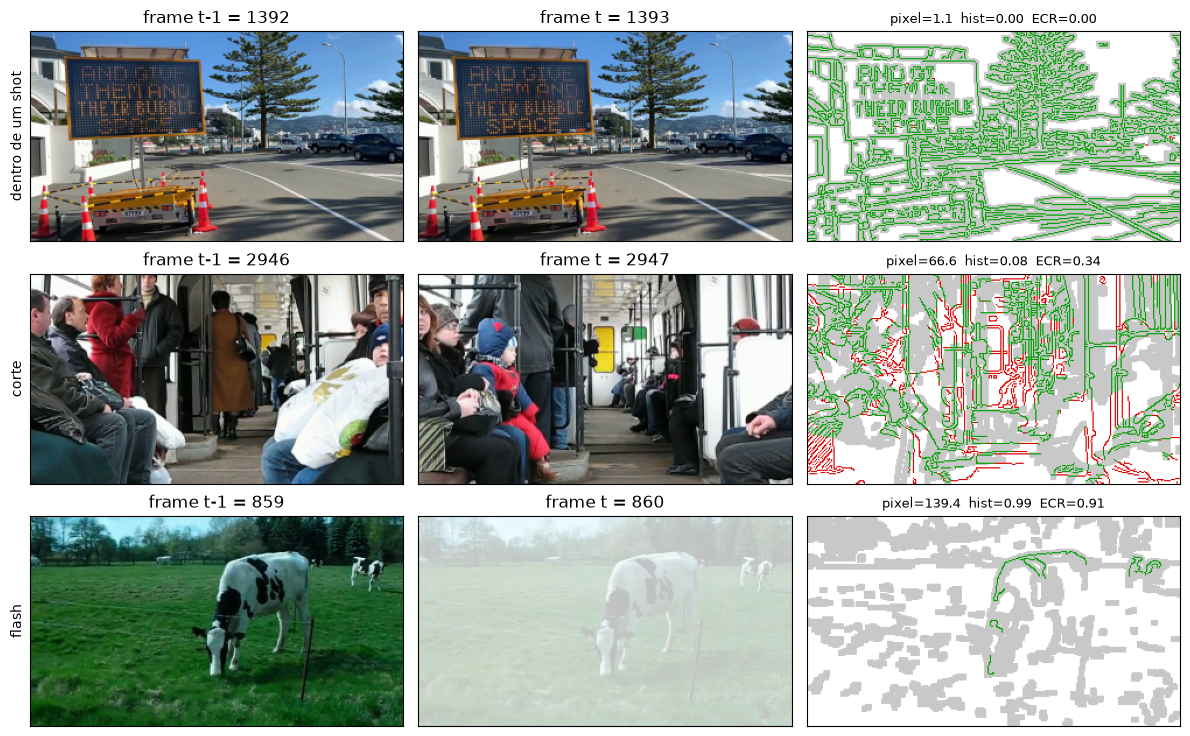

In [26]:
def ecr_overlay(f_prev, f_t):
    # cinzento = arestas dilatadas de t-1; verde = arestas de t perto de t-1; vermelho = arestas que entram
    e_prev, d_prev = compute_edges(f_prev)
    e_t, _ = compute_edges(f_t)
    img = np.full(e_t.shape + (3,), 255, np.uint8)
    img[d_prev] = (200, 200, 200)
    img[e_t & d_prev] = (0, 160, 0)
    img[e_t & ~d_prev] = (220, 0, 0)
    return img

data = dev_data["dev_01"]
sig = data["signals"]
longest = max(data["gt"]["shots"], key=lambda s: s["end"] - s["start"])
cut_frames = [trans["start"] for trans in data["gt"]["transitions"]]

pairs = [("dentro de um shot", (longest["start"] + longest["end"]) // 2),
         ("corte", min(cut_frames, key=lambda t: sig["Histogram Distance (Chi2)"][t])),
         ("flash", data["gt"]["distractors"][0]["start"])]

fig, axs = plt.subplots(3, 3, figsize=(12, 7.5))
for row, (label, t) in enumerate(pairs):
    f_prev, f_t = data["frames"][t - 1], data["frames"][t]
    axs[row][0].imshow(cv2.cvtColor(f_prev, cv2.COLOR_BGR2RGB))
    axs[row][0].set_title(f"frame t-1 = {t - 1}")
    axs[row][1].imshow(cv2.cvtColor(f_t, cv2.COLOR_BGR2RGB))
    axs[row][1].set_title(f"frame t = {t}")
    axs[row][2].imshow(ecr_overlay(f_prev, f_t))
    axs[row][2].set_title(f"pixel={sig['Pixel Difference'][t]:.1f}  hist={sig['Histogram Distance (Chi2)'][t]:.2f}  "
                          f"ECR={sig['ECR'][t]:.2f}", fontsize=9)
    axs[row][0].set_ylabel(label)
    for ax in axs[row]:
        ax.set_xticks([])
        ax.set_yticks([])
plt.tight_layout()
plt.show()

#### Escolha do espaço de cor e do número de *bins*
Para cada configuração calculamos o sinal de histograma no DEV e guardamos o melhor $F_1$ ao varrer o limiar.

In [27]:
configs = [("hsv", (8, 8)), ("hsv", (16, 16)), ("hsv", (32, 32)), ("rgb", (8, 8, 8)), ("rgb", (16, 16, 16))]

print(f"{'Espaço':<8} | {'Bins':<10} | {'Melhor T':<9} | {'F1':<6}")
print("-" * 42)
for space, bins in configs:
    sigs = {name: compute_histogram_signal(data["frames"], bins=bins, space=space) for name, data in dev_data.items()}
    best_f1, best_t = 0.0, 0.0
    for t in np.linspace(0, 1, 101):
        p, r, f1, _ = evaluate_cuts({name: detect_cuts(sigs[name], t) for name in dev_data})
        if f1 > best_f1:
            best_f1, best_t = f1, t
    print(f"{space:<8} | {'x'.join(map(str, bins)):<10} | {best_t:<9.2f} | {best_f1:<6.3f}")

Espaço   | Bins       | Melhor T  | F1    
------------------------------------------
hsv      | 8x8        | 0.21      | 0.887 
hsv      | 16x16      | 0.24      | 0.887 
hsv      | 32x32      | 0.29      | 0.895 
rgb      | 8x8x8      | 0.11      | 0.908 
rgb      | 16x16x16   | 0.19      | 0.908 


#### Deliverable — Gráfico dos Sinais (~30 Segundos)
Visualização dos três sinais de dissimilaridade em 30 segundos do vídeo `dev_01`, com as linhas verticais dos cortes reais e *flashes* do *ground-truth* sobrepostas. Escolhemos uma janela que começa 10 s antes do primeiro *flash*, para se ver como cada sinal reage a ele.

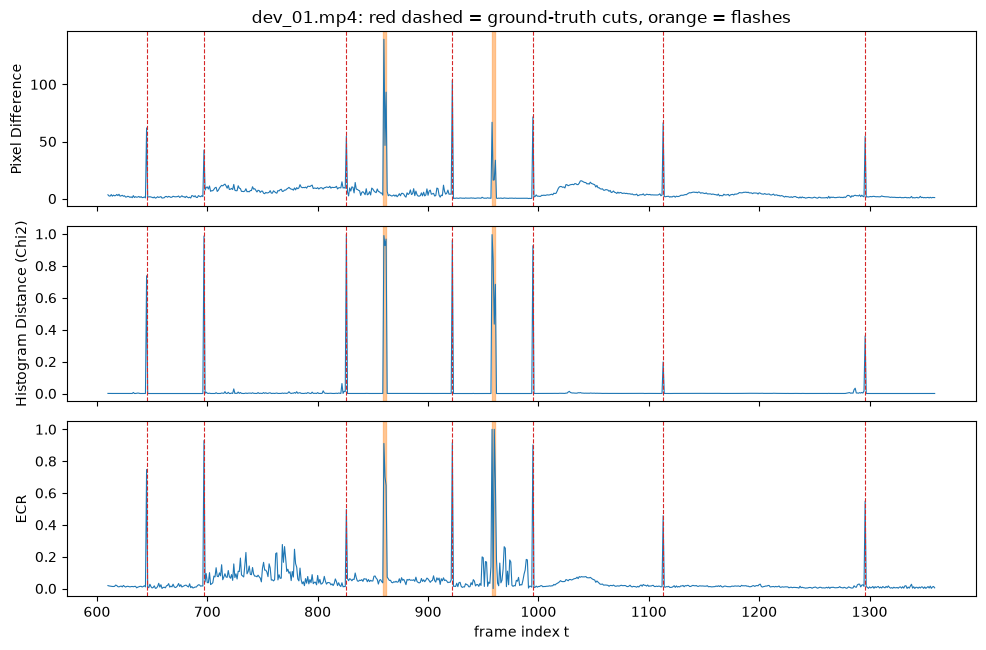

In [28]:
dev01_gt = dev_data["dev_01"]["gt"]
fps = dev01_gt.get("fps", 25)

# 30 segundos a começar 10 s antes do primeiro flash
first_flash = dev01_gt["distractors"][0]["start"] if dev01_gt["distractors"] else 0
start = max(0, first_flash - 10 * fps)

plotting.plot_signals(
    signals=dev_data["dev_01"]["signals"],
    gt=dev01_gt,
    start=start,
    end=start + 30 * fps
)
plt.show()

#### Deliverable — Varrimento de Limiares e Tabela de Comparação
A escolha dos limiares ($T$) é efetuada no conjunto total de desenvolvimento (`DEV` = `dev_01` + `dev_02`). Para cada sinal, varia-se o limiar $T$ ao longo de um intervalo de valores, contabilizando $TP$, $FP$ e $FN$ com a função `metrics.match_cuts`.

Um corte é declarado em $t$ quando $d(t) > T$ e $d(t)$ é o máximo local numa janela de $\pm 5$ frames (`detect_cuts`). Sem esta condição, quando duas frames seguidas passam o limiar no mesmo corte, a segunda conta como falso positivo.

In [29]:
signal_names = ["Pixel Difference", "Histogram Distance (Chi2)", "ECR"]
pr_curves_data = {}
best_results = {}

for s_name in signal_names:
    # Determinar valor máximo do sinal em todo o DEV
    max_val = max(np.max(dev_data[v]["signals"][s_name]) for v in dev_data)
    thresholds = np.linspace(0, max_val, 200)

    points = []
    best_f1, best_p, best_r, best_t = -1.0, 0.0, 0.0, 0.0

    for t in thresholds:
        total_tp, total_fp, total_fn = 0, 0, 0

        for name, data in dev_data.items():
            sig = data["signals"][s_name]
            gt_cuts = [trans["start"] for trans in data["gt"]["transitions"] if trans["type"] == "cut"]
            pred_cuts = detect_cuts(sig, t)

            tp, fp, fn = metrics.match_cuts(gt_cuts, pred_cuts)
            total_tp += tp
            total_fp += fp
            total_fn += fn

        p, r, f1 = metrics.precision_recall_f1(total_tp, total_fp, total_fn)
        points.append((t, p, r))

        if f1 > best_f1:
            best_f1, best_p, best_r, best_t = f1, p, r, t

    pr_curves_data[s_name] = points
    best_results[s_name] = (best_t, best_p, best_r, best_f1)

# Imprimir Tabela Formatada para o Relatório (com os flashes que deram falso alarme)
print(f"{'Sinal':<28} | {'Limiar Ótimo (T)':<16} | {'Precision':<10} | {'Recall':<10} | {'F1-Score':<10} | {'Flash-FA':<8}")
print("-" * 93)
for s_name, (t, p, r, f1) in best_results.items():
    _, _, _, fa = evaluate_cuts({name: detect_cuts(data["signals"][s_name], t) for name, data in dev_data.items()})
    print(f"{s_name:<28} | {t:<16.4f} | {p:<10.3f} | {r:<10.3f} | {f1:<10.3f} | {fa}/{num_flashes}")

Sinal                        | Limiar Ótimo (T) | Precision  | Recall     | F1-Score   | Flash-FA
---------------------------------------------------------------------------------------------
Pixel Difference             | 46.9135          | 0.815      | 0.943      | 0.874      | 12/12
Histogram Distance (Chi2)    | 0.1104           | 0.841      | 0.986      | 0.908      | 12/12
ECR                          | 0.4472           | 0.631      | 0.929      | 0.751      | 11/12


#### Deliverable — Curvas Precision-Recall (PR)
Visualização das curvas PR obtidas no varrimento de limiares para os três sinais de dissimilaridade no conjunto `DEV`. Os pontos de $F_1$ máximo de cada sinal encontram-se marcados no gráfico.

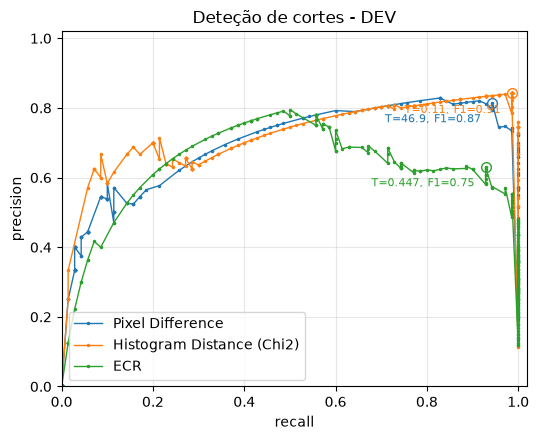

In [30]:
# Gerar o gráfico das curvas PR usando a função dada
plotting.plot_pr_curve(pr_curves_data, title="Deteção de cortes - DEV")
plt.show()

#### Combinação de sinais
O histograma falha em cortes entre planos de cores parecidas, e o ECR e a diferença de píxeis reagem a movimento e *flashes*. Por isso testamos um detetor combinado: os candidatos são os picos do melhor sinal (acima do seu limiar) e só são aceites se outro sinal também estiver acima do seu limiar no mesmo frame. Os dois limiares são escolhidos em conjunto, numa grelha no DEV.

In [31]:
best_signal = max(best_results, key=lambda s: best_results[s][3])
print(f"Sinal principal: {best_signal} (F1 sozinho = {best_results[best_signal][3]:.3f})\n")

combo_results = {}
for confirm_name in signal_names:
    if confirm_name == best_signal:
        continue
    max_main = best_results[best_signal][0] * 1.5      # com confirmação, o limiar principal pode baixar
    max_conf = max(np.max(dev_data[v]["signals"][confirm_name]) for v in dev_data)

    best = (0.0, 0.0, 0.0, 0.0, -1.0, 0)      # (t1, t2, p, r, f1, flash-FA)
    for t1 in np.linspace(0, max_main, 30):
        for t2 in np.linspace(0, max_conf, 30):
            preds = {name: detect_cuts_combined(data["signals"][best_signal], t1, data["signals"][confirm_name], t2)
                     for name, data in dev_data.items()}
            p, r, f1, fa = evaluate_cuts(preds)
            if f1 > best[4]:
                best = (t1, t2, p, r, f1, fa)
    combo_results[confirm_name] = best

print(f"{'Confirmação':<28} | {'T principal':<11} | {'T confirm.':<10} | {'Precision':<10} | {'Recall':<10} | {'F1-Score':<10} | {'Flash-FA':<8}")
print("-" * 103)
for confirm_name, (t1, t2, p, r, f1, fa) in combo_results.items():
    print(f"{confirm_name:<28} | {t1:<11.4f} | {t2:<10.4f} | {p:<10.3f} | {r:<10.3f} | {f1:<10.3f} | {fa}/{num_flashes}")

Sinal principal: Histogram Distance (Chi2) (F1 sozinho = 0.908)

Confirmação                  | T principal | T confirm. | Precision  | Recall     | F1-Score   | Flash-FA
-------------------------------------------------------------------------------------------------------
Pixel Difference             | 0.0400      | 33.3024    | 0.843      | 1.000      | 0.915      | 12/12
ECR                          | 0.0914      | 0.3793     | 0.852      | 0.986      | 0.914      | 12/12


#### Configuração escolhida
A configuração com melhor $F_1$ no DEV (sinal sozinho ou combinação) é usada em `tp1.py`, nas constantes do início do ficheiro.

In [32]:
tp1_names = {"Pixel Difference": "pixel", "Histogram Distance (Chi2)": "histogram", "ECR": "ecr"}
best_combo = max(combo_results, key=lambda c: combo_results[c][4])

if combo_results[best_combo][4] > best_results[best_signal][3]:
    t1, t2 = combo_results[best_combo][:2]
    print(f'CUT_SIGNAL = "{tp1_names[best_signal]}"')
    print(f"CUT_THRESHOLD = {t1:.4f}")
    print(f'CONFIRM_SIGNAL = "{tp1_names[best_combo]}"')
    print(f"CONFIRM_THRESHOLD = {t2:.4f}")
else:
    print(f'CUT_SIGNAL = "{tp1_names[best_signal]}"')
    print(f"CUT_THRESHOLD = {best_results[best_signal][0]:.4f}")
    print("CONFIRM_SIGNAL = None")

CUT_SIGNAL = "histogram"
CUT_THRESHOLD = 0.0400
CONFIRM_SIGNAL = "pixel"
CONFIRM_THRESHOLD = 33.3024


#### Discussão
- **O histograma é o sinal isolado mais fiável** ($F_1$ = 0.908): dentro dos *shots* fica praticamente a zero, porque um histograma ignora a posição das cores e é pouco afetado pelo movimento. Falha sobretudo em cortes entre planos de cores parecidas.
- **O ECR é o mais sensível ao movimento** ($F_1$ = 0.751, precisão 0.631): com a câmara em movimento muitas arestas deslocam-se mais do que a dilatação tolera, o que gera vários picos de 0.2–0.3 dentro dos *shots* (visível no gráfico dos sinais).
- **A diferença de píxeis** fica a meio ($F_1$ = 0.874): reage a cortes mas também a qualquer variação global de intensidade.
- **Combinar sinais ajuda**: exigir que o histograma e a diferença de píxeis estejam ambos acima do limiar dá recall 1.000 e $F_1$ = 0.915. A confirmação com o ECR dá um resultado quase igual (0.914), o que indica que o ganho vem de exigir dois sinais e não de um sinal em particular.
- **Os *flashes* enganam todos os sinais** (12/12 com o detetor escolhido): um *flash* muda bruscamente a cor, a intensidade e as arestas da imagem, por isso nenhum limiar o separa de um corte. Quase todos os falsos positivos que restam vêm de *flashes*, e é isso que a verificação da Parte 2 vai atacar.

## 3. Part 2 - False alarms

## 4. Part 3 - Recurring scenes

## 5. Results (development and test)

## 6. Analysis and failure cases

## 7. Conclusion and self-evaluation

## 8. Extras

## 9. Use of AI tools